# 03 · The model

**Question:** using only what is known before departure, how well can we tell which flights will arrive 15 or more minutes late?

The models are trained by `src/train.py` (about 15 minutes), which saves its scores and predictions. This notebook loads those results and explains them. To retrain, run `.venv\Scripts\python src\train.py` from the project folder.

**How the flights are split, by date:**

| Part | Months | Used for |
|---|---|---|
| Train | Sep 2025 – May 2026 | The model learns from these flights |
| Validate | Jun 2026 | Deciding when the model stops growing, and choosing settings |
| Test | Jul – Aug 2026 | The reported scores. Looked at once, at the end |

**The four models:**

1. **Always on time.** Gives every flight the same low risk. This is the floor.
2. **Logistic regression.** A simple, classic model on the schedule features.
3. **LightGBM, schedule only.** The main model type, using only the timetable.
4. **LightGBM, all features.** Adds the aircraft rotation and aircraft details.

## 1. Load the results

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "load.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import plotstyle as ps
from features import TARGET
from train import ALL_FEATURES, IMPORTANCE_CSV, METRICS_CSV, NOT_USED, PREDICTIONS_PARQUET, SCHEDULE_FEATURES

ps.apply_style()
metrics = pd.read_csv(METRICS_CSV)
importance = pd.read_csv(IMPORTANCE_CSV)
predictions = pd.read_parquet(PREDICTIONS_PARQUET)
test = predictions[predictions["split"] == "test"]

print(f"Schedule-only model: {len(SCHEDULE_FEATURES)} features")
print(f"All-features model:  {len(ALL_FEATURES)} features")
print(f"Left out on purpose: {', '.join(NOT_USED)}")
print(f"Test flights scored: {len(test):,}")

Schedule-only model: 10 features
All-features model:  17 features
Left out on purpose: month, day_of_month, days_from_holiday
Test flights scored: 1,206,245


**Why three calendar features are left out.** The data covers one year. July and August never appear in training, so `month` cannot be learned. And `day_of_month` together with `days_from_holiday` and the weekday pins down an exact date, which lets the model memorize single bad days (one storm on one Sunday) instead of patterns that repeat. With those features the model stopped improving on the validation month almost at once. With several years of data they would be worth adding back.

## 2. Scores on the test months

How to read the scores:

- **ROC-AUC:** pick one late flight and one on-time flight at random. ROC-AUC is how often the model gives the late one the higher risk. 0.5 is guessing, 1.0 is perfect.
- **PR-AUC:** a similar score that concentrates on the late flights. Guessing scores the share of late flights (the `late_rate` column), so compare against that.
- **Late rate in the riskiest 10%:** of the tenth of flights the model worries about most, the share that really arrived late.

In [2]:
MODEL_ORDER = ["Always on time", "Logistic regression", "LightGBM, schedule only", "LightGBM, all features"]

def scores(split: str, group: str) -> pd.DataFrame:
    rows = metrics[(metrics["split"] == split) & (metrics["group"] == group)].set_index("model").loc[MODEL_ORDER]
    return rows[["flights", "late_rate", "roc_auc", "pr_auc", "late_rate_in_riskiest_10pct"]].round(3)

test_scores = scores("test", "All flights")
test_scores

,flights,late_rate,roc_auc,pr_auc,late_rate_in_riskiest_10pct
model,,,,,
Always on time,1206245,0.276,0.500,0.276,0.276
Logistic regression,1206245,0.276,0.689,0.431,0.503
"LightGBM, schedule only",1206245,0.276,0.704,0.461,0.548
"LightGBM, all features",1206245,0.276,0.713,0.476,0.567


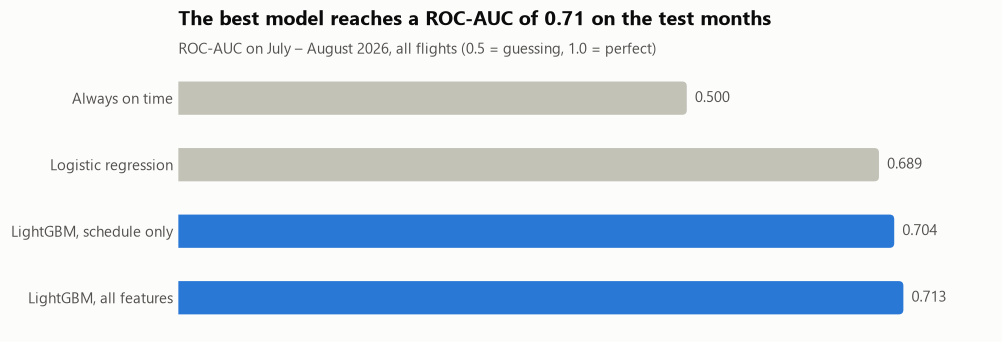

In [3]:
positions = list(range(len(test_scores)))
colors = [ps.BLUE if "LightGBM" in name else ps.AXIS for name in test_scores.index]

fig, ax = plt.subplots(figsize=(9, 3))
ax.set_xlim(0, 0.8)
ax.set_ylim(len(test_scores) - 0.5, -0.5)
ax.set_yticks(positions, test_scores.index)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
best = test_scores["roc_auc"].max()
ps.title(ax, f"The best model reaches a ROC-AUC of {best:.2f} on the test months",
         "ROC-AUC on July – August 2026, all flights (0.5 = guessing, 1.0 = perfect)")
ps.barh_rounded(ax, positions, test_scores["roc_auc"].tolist(), colors, height=0.5)
for pos, value in zip(positions, test_scores["roc_auc"]):
    ax.text(value + 0.008, pos, f"{value:.3f}", va="center", ha="left", color=ps.INK_2)
ps.save(fig, "model_roc_auc")
plt.show()

## 3. Validation and test side by side

In [4]:
side_by_side = pd.DataFrame({
    "validate (June)": scores("validate", "All flights")["roc_auc"],
    "test (July – August)": scores("test", "All flights")["roc_auc"],
})
side_by_side

,validate (June),test (July – August)
model,,
Always on time,0.500,0.500
Logistic regression,0.684,0.689
"LightGBM, schedule only",0.705,0.704
"LightGBM, all features",0.716,0.713


## 4. Does a higher predicted risk mean more late flights?

Sort the test flights by the model's predicted risk and cut them into ten equal groups. If the model is useful, the share of late flights should climb from group 1 (safest) to group 10 (riskiest).

In [5]:
group = pd.qcut(test["risk_all_features"].rank(method="first"), 10, labels=range(1, 11))
by_group = test.groupby(group, observed=True).agg(
    actual=(TARGET, "mean"), predicted=("risk_all_features", "mean"), flights=(TARGET, "size"))
by_group[["actual", "predicted"]] *= 100
by_group.index.name = "risk_group"
by_group.rename(columns={"actual": "actually_late_%", "predicted": "predicted_risk_%"}).round(1)

,actually_late_%,predicted_risk_%,flights
risk_group,,,
1,6.8,6.400000,120625
2,11.2,10.100000,120624
3,15.5,12.700000,120625
4,19.2,15.200000,120624
5,23.3,17.700001,120625
6,27.9,20.600000,120624
7,32.6,23.900000,120624
8,37.9,27.900000,120625
9,45.0,33.299999,120624


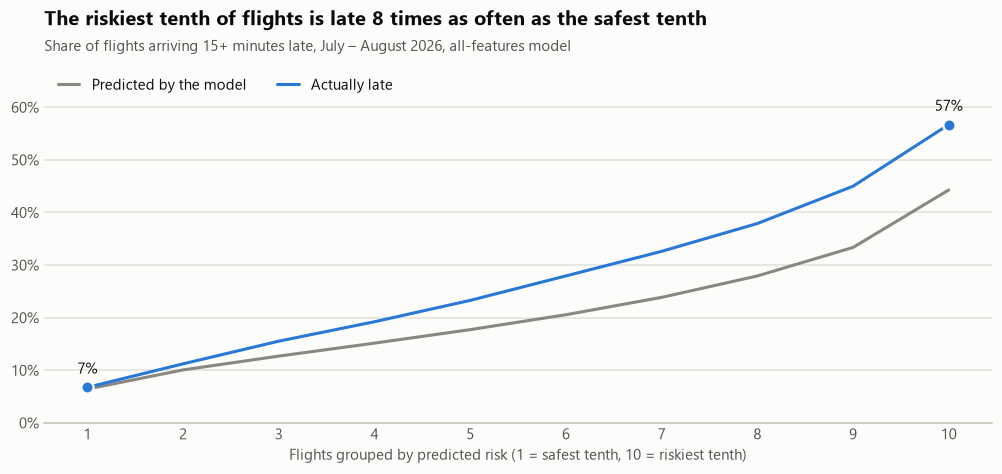

In [6]:
x = list(range(len(by_group)))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, by_group["predicted"], color=ps.MUTED, label="Predicted by the model", zorder=2)
ax.plot(x, by_group["actual"], color=ps.BLUE, label="Actually late", zorder=3)
for i in (0, len(by_group) - 1):
    ax.plot(i, by_group["actual"].iloc[i], marker="o", markersize=8, color=ps.BLUE,
            markeredgecolor=ps.SURFACE, markeredgewidth=1.5, zorder=4)
    ax.annotate(f"{by_group['actual'].iloc[i]:.0f}%", (i, by_group["actual"].iloc[i]),
                xytext=(0, 9), textcoords="offset points", ha="center", color=ps.INK)
ax.set_xticks(x, by_group.index)
ax.set_xlabel("Flights grouped by predicted risk (1 = safest tenth, 10 = riskiest tenth)")
ax.set_ylim(0, max(by_group["actual"].max(), by_group["predicted"].max()) * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(loc="upper left", ncols=2, handlelength=1.4)
ratio = by_group["actual"].iloc[-1] / by_group["actual"].iloc[0]
ps.title(ax, f"The riskiest tenth of flights is late {ratio:.0f} times as often as the safest tenth",
         "Share of flights arriving 15+ minutes late, July – August 2026, all-features model")
ps.save(fig, "model_risk_groups")
plt.show()

## 5. Delta

In [7]:
scores("test", "Delta")

,flights,late_rate,roc_auc,pr_auc,late_rate_in_riskiest_10pct
model,,,,,
Always on time,181238,0.238,0.500,0.238,0.238
Logistic regression,181238,0.238,0.674,0.371,0.431
"LightGBM, schedule only",181238,0.238,0.672,0.377,0.448
"LightGBM, all features",181238,0.238,0.684,0.392,0.469


## 6. Did the leakage guard hold?

In notebook 02, 5% of flights were flown by an aircraft swapped in on the day, and more than half of them arrived late. Their rotation features were replaced with usual values so the model could not spot them. If the guard works, the model should give these flights an ordinary risk, well below their real late rate.

In [8]:
guard = metrics[(metrics["split"] == "test") & (metrics["model"] == "LightGBM, all features")
                & metrics["group"].isin(["Recorded aircraft fits the schedule", "Aircraft swapped in on the day"])]
guard = guard.set_index("group")[["flights", "late_rate", "average_predicted_risk", "roc_auc"]]
(guard.assign(late_rate=lambda d: (100 * d["late_rate"]).round(1),
              average_predicted_risk=lambda d: (100 * d["average_predicted_risk"]).round(1))
      .rename(columns={"late_rate": "actually_late_%", "average_predicted_risk": "average_predicted_risk_%"})
      .round(3))

,flights,actually_late_%,average_predicted_risk_%,roc_auc
group,,,,
Recorded aircraft fits the schedule,1136541,25.5,21.0,0.715
Aircraft swapped in on the day,69704,62.7,24.3,0.670


## 7. Which features does the model lean on?

This counts how much each feature improved the model's decisions during training. It is a rough first look. Notebook 04 uses SHAP, which explains individual predictions and is the better tool.

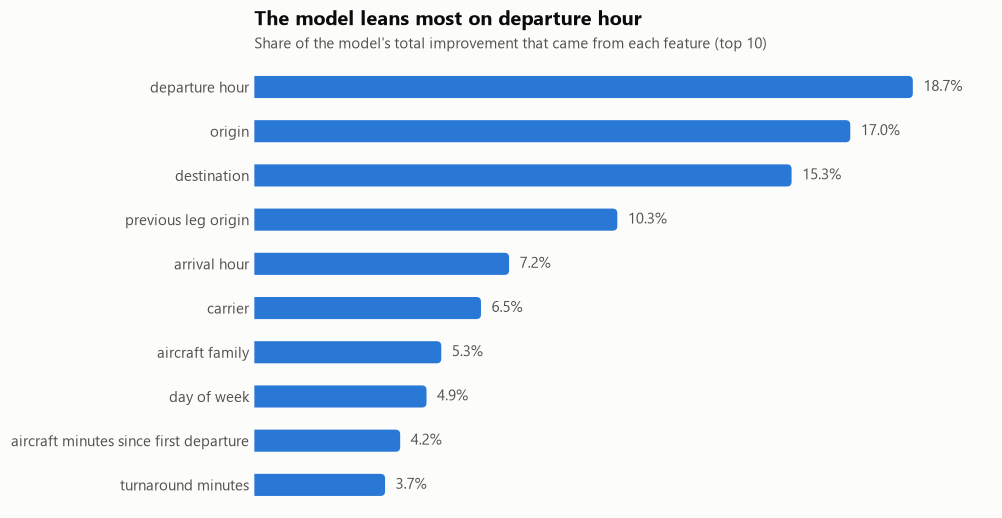

In [9]:
top = importance[importance["model"] == "LightGBM, all features"].head(10).set_index("feature")["gain_share_%"]
positions = list(range(len(top)))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.set_xlim(0, top.max() * 1.12)
ax.set_ylim(len(top) - 0.5, -0.5)
ax.set_yticks(positions, [name.replace("_", " ") for name in top.index])
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ps.title(ax, f"The model leans most on {top.index[0].replace('_', ' ')}",
         "Share of the model's total improvement that came from each feature (top 10)")
ps.barh_rounded(ax, positions, top.tolist(), ps.BLUE, height=0.5)
for pos, value in zip(positions, top):
    ax.text(value + 0.3, pos, f"{value:.1f}%", va="center", ha="left", color=ps.INK_2)
ps.save(fig, "model_feature_importance")
plt.show()

## What we learned

1. **The best model scores a ROC-AUC of 0.713 on the test months.** That is inside the 0.65–0.75 range set as realistic at the start of the project. Logistic regression scores 0.689, and LightGBM on the schedule alone scores 0.704.
2. **The score holds up on unseen months.** It is 0.716 on June and 0.713 on July–August, so the model did not just fit the validation month.
3. **The ranking is useful.** In the tenth of flights the model worries about most, 57% arrive late. In the safest tenth, 7% do.
4. **The model underestimates summer.** In every risk group, more flights were late than the model predicted (57% against 44% in the riskiest group). It learned from calmer months. The ranking can be trusted; the percentages would need recalibrating on recent data before real use.
5. **The aircraft features add a little.** They lift ROC-AUC from 0.704 to 0.713. Because they rely on the aircraft that actually flew, the conservative result to quote is **0.704**.
6. **Delta is harder to predict (0.684).** Inside one airline the airline feature cannot help, and Delta's delays come mostly from its own operations, which a timetable does not show.
7. **The leakage guard held.** Flights with a swapped-in aircraft were late 63% of the time, and the model gave them an average risk of 24%, close to ordinary flights. It could not spot them.

## What the model cannot see

Weather, air traffic control restrictions, and what happens on the day are not in a timetable. They cause a large share of delays, which is why a schedule-based model tops out near 0.7. Adding weather forecasts is the most promising next step.

## Next

**Notebook 04:** SHAP explanations, which show how each feature pushes a single prediction up or down, with a focus on Delta flights.

Charts from this notebook are saved in `reports/figures/`.